Python is currently looking for files in: d:\Industrial_vision


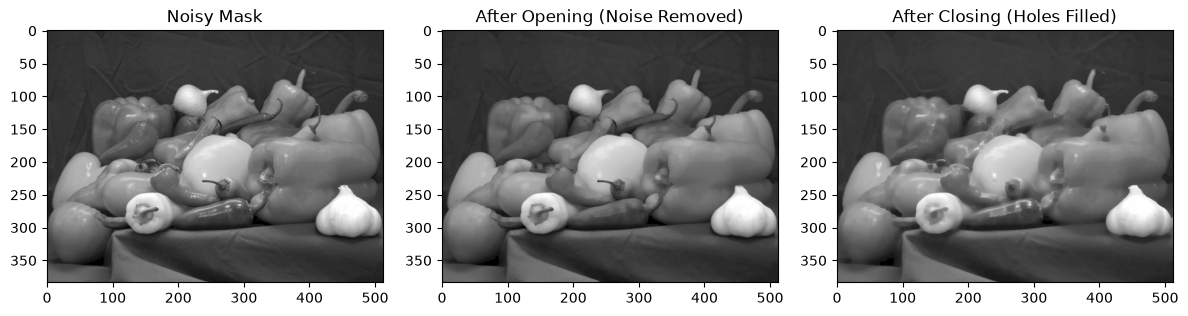

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
print("Python is currently looking for files in:", os.getcwd())

img = cv2.imread('peppers.png', cv2.IMREAD_GRAYSCALE)

kernel = np.ones((5, 5), np.uint8)

opening = cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel)

closing = cv2.morphologyEx(img, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1), plt.imshow(img, cmap='gray'), plt.title('Noisy Mask')
plt.subplot(1, 3, 2), plt.imshow(opening, cmap='gray'), plt.title('After Opening (Noise Removed)')
plt.subplot(1, 3, 3), plt.imshow(closing, cmap='gray'), plt.title('After Closing (Holes Filled)')
plt.tight_layout()
plt.show()


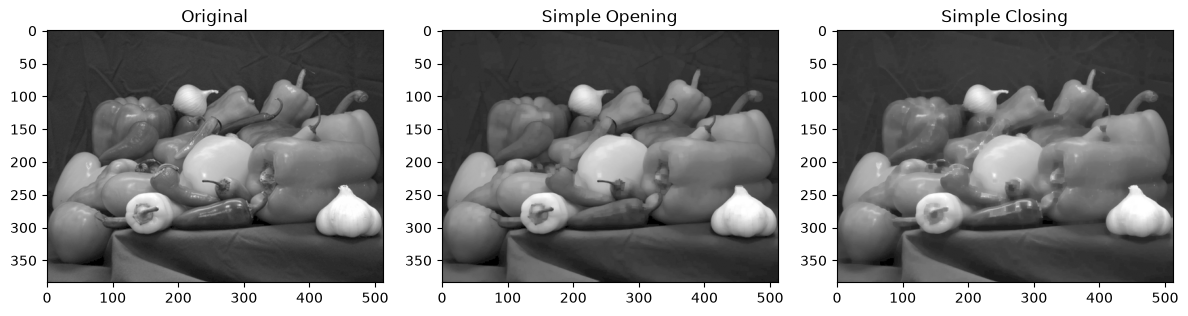

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

img = cv2.imread('peppers.png', cv2.IMREAD_GRAYSCALE)
h, w = img.shape
kernel_size = 5
p = kernel_size // 2  # Padding size (2)

padded_0 = np.pad(img, p, mode='constant', constant_values=0)
padded_255 = np.pad(img, p, mode='constant', constant_values=255)

erode = np.zeros_like(img)
for i in range(h):
    for j in range(w):
        erode[i, j] = np.min(padded_255[i:i+5, j:j+5])

dilate = np.zeros_like(img)
for i in range(h):
    for j in range(w):
        dilate[i, j] = np.max(padded_0[i:i+5, j:j+5])


padded_erode = np.pad(erode, p, mode='constant', constant_values=0)
opening = np.zeros_like(img)
for i in range(h):
    for j in range(w):
        opening[i, j] = np.max(padded_erode[i:i+5, j:j+5])


padded_dilate = np.pad(dilate, p, mode='constant', constant_values=255)
closing = np.zeros_like(img)
for i in range(h):
    for j in range(w):
        closing[i, j] = np.min(padded_dilate[i:i+5, j:j+5])

# Plot results
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1), plt.imshow(img, cmap='gray'), plt.title('Original')
plt.subplot(1, 3, 2), plt.imshow(opening, cmap='gray'), plt.title('Simple Opening')
plt.subplot(1, 3, 3), plt.imshow(closing, cmap='gray'), plt.title('Simple Closing')
plt.tight_layout()
plt.show()
